In [3]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.918 seconds
All requested packages already installed.


In [4]:
!mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.864 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [6]:
# Список файлов с заказами
orders_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

# Проверяем расположение файлов
if all(os.path.exists(f) for f in orders_files):
    paths = orders_files
elif all(os.path.exists(os.path.join("data", f)) for f in orders_files):
    paths = [os.path.join("data", f) for f in orders_files]
else:
    raise FileNotFoundError(
        "Не удалось найти все три CSV-файла. "
        "Проверь расположение файлов."
    )

# Загружаем и объединяем данные
df_orders = pd.concat(
    [pd.read_csv(f) for f in paths],
    ignore_index=True
)

# Проверяем результат
print("Количество строк и столбцов:", df_orders.shape)

print("\nНазвания столбцов:")
print(df_orders.columns.tolist())

print("\nПервые 5 строк:")
display(df_orders.head())

Количество строк и столбцов: (15000, 7)

Названия столбцов:
['order_id', 'user_id', 'order_datetime', 'product_id', 'price', 'quantity', 'status']

Первые 5 строк:


,order_id,user_id,order_datetime,product_id,price,quantity,status
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid


In [7]:
# Преобразование цены в числовой формат
df_orders["price"] = pd.to_numeric(
    df_orders["price"],
    errors="coerce"
)

# Проверка структуры данных
print("Типы данных:")
print(df_orders.dtypes)

print("\nКоличество пропусков:")
print(df_orders.isnull().sum())

print("\nОсновные статистические показатели цены:")
print(df_orders["price"].describe())

Типы данных:
order_id            int64
user_id             int64
order_datetime        str
product_id          int64
price             float64
quantity            int64
status                str
dtype: object

Количество пропусков:
order_id          0
user_id           0
order_datetime    0
product_id        0
price             0
quantity          0
status            0
dtype: int64

Основные статистические показатели цены:
count    15000.000000
mean     10207.380061
std       5657.476724
min        300.260000
25%       5304.957500
50%      10267.210000
75%      15050.532500
max      19998.960000
Name: price, dtype: float64


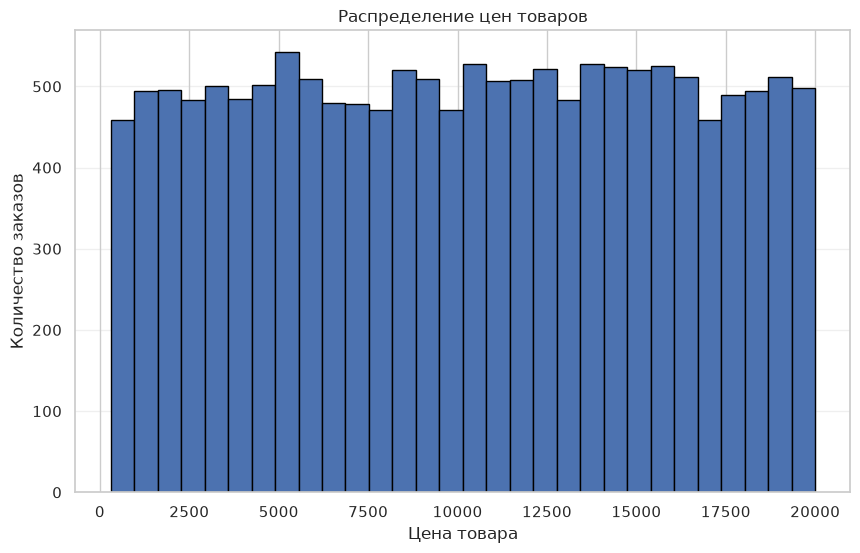

In [8]:
plt.figure(figsize=(10, 6))

plt.hist(
    df_orders["price"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Распределение цен товаров")
plt.xlabel("Цена товара")
plt.ylabel("Количество заказов")

plt.grid(axis="y", alpha=0.3)
plt.show()

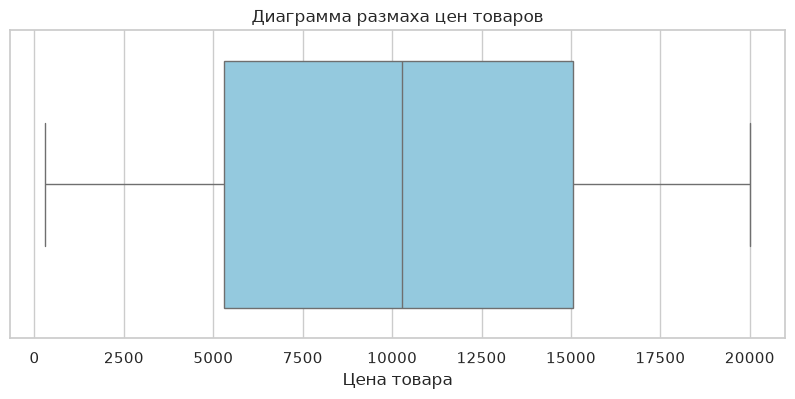

In [9]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df_orders["price"],
    color="skyblue"
)

plt.title("Диаграмма размаха цен товаров")
plt.xlabel("Цена товара")

plt.show()

In [10]:
# Вычисление квартилей
q1 = df_orders["price"].quantile(0.25)
q3 = df_orders["price"].quantile(0.75)

# Межквартильный размах
iqr = q3 - q1

# Границы выбросов
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Выделение выбросов
outliers = df_orders[
    (df_orders["price"] < lower) |
    (df_orders["price"] > upper)
]

# Вывод результатов
print("Первый квартиль (Q1):", q1)
print("Третий квартиль (Q3):", q3)
print("Межквартильный размах (IQR):", iqr)

print("\nНижняя граница:", lower)
print("Верхняя граница:", upper)

print("\nКоличество выбросов:", len(outliers))
print("Доля выбросов, %:",
      round(len(outliers) / df_orders["price"].notna().sum() * 100, 2))

print("\nПервые найденные выбросы:")
display(outliers.head(10))

Первый квартиль (Q1): 5304.9575
Третий квартиль (Q3): 15050.532500000001
Межквартильный размах (IQR): 9745.575

Нижняя граница: -9313.405
Верхняя граница: 29668.895000000004

Количество выбросов: 0
Доля выбросов, %: 0.0

Первые найденные выбросы:


,order_id,user_id,order_datetime,product_id,price,quantity,status


Количество заказов по статусам:
status
paid         12032
cancelled     2212
refunded       756
Name: count, dtype: int64


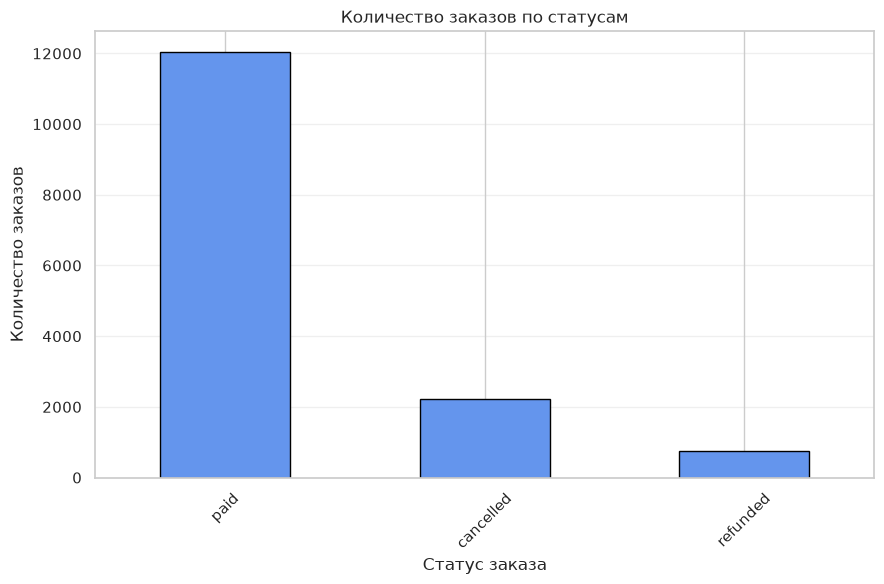

In [11]:
# Подсчёт количества заказов по статусам
status_counts = (
    df_orders["status"]
    .fillna("Не указан")
    .value_counts()
)

print("Количество заказов по статусам:")
print(status_counts)

# Построение диаграммы
plt.figure(figsize=(9, 6))

status_counts.plot(
    kind="bar",
    color="cornflowerblue",
    edgecolor="black"
)

plt.title("Количество заказов по статусам")
plt.xlabel("Статус заказа")
plt.ylabel("Количество заказов")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
price_mean = df_orders["price"].mean()
price_median = df_orders["price"].median()
price_min = df_orders["price"].min()
price_max = df_orders["price"].max()

print("Средняя цена:", round(price_mean, 2))
print("Медианная цена:", round(price_median, 2))
print("Минимальная цена:", round(price_min, 2))
print("Максимальная цена:", round(price_max, 2))

print("\nНаиболее распространённые статусы:")
print(status_counts.head())

Средняя цена: 10207.38
Медианная цена: 10267.21
Минимальная цена: 300.26
Максимальная цена: 19998.96

Наиболее распространённые статусы:
status
paid         12032
cancelled     2212
refunded       756
Name: count, dtype: int64
